# Problem Overview
**Predicting Annual Solar Energy Production from project features**

* **Task:** Supervised regression
* **Target:** `Estimated Annual PV Energy Production (kWh)` (modelled as `log1p(y)` and converted back to kWh for evaluation)
* **Dataset:** `Cleaned_Dataset.csv` (output of the pre-processing notebook)
* **Models:** Linear Regression, XGBoost, LightGBM, CatBoost
* **Metrics:** MAE, RMSE and R² on the 20% hold-out test set (original kWh scale)

**Contents**
1. Import Libraries
2. Load Data
3. Basic Understanding
4. Train–Test Split
5. Feature Engineering
6. Define Feature Groups
7. Preprocessing Pipeline
8. Define Models
9. Evaluation Function and Pipeline function
10. Train and Evaluate Baseline Models
11. Hyper-parameter Tuning
12. Compare Models and Select the Best
13. Save the Best Model
14. Summary

### 1. Import

In [43]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split, KFold, GridSearchCV
from sklearn.preprocessing import OneHotEncoder, StandardScaler, FunctionTransformer, TargetEncoder
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LinearRegression

from sklearn import metrics

import lightgbm as lgb
from catboost import CatBoostRegressor
from xgboost import XGBRegressor

import warnings
warnings.filterwarnings("ignore")

### 2. Load Data

In [23]:
data = pd.read_csv(r"D:\OJT\Solar_Energy_Production_Analysis\data\Cleaned_Dataset.csv")

# Make sure data is loaded sucessfully
data.head(3)

,Project ID,Interconnection Date,Utility,City/Town,County,Zip,Division,Substation,Developer,Metering Method,Estimated PV System Size (kWdc),PV System Size (kWac),Estimated Annual PV Energy Production (kWh),Energy Storage System Size (kWac)
0,SDG-66301,12/29/2023,Con Ed,Richmond Hill,Queens,11418.0,CENY-BK,Brownsville_2,Kamtech Solar Solutions,NM,6.05,5.17,7100,NaN
1,SDG-66299,12/29/2023,Con Ed,Bronx,Bronx,10473.0,CENY-BX,Parkchester_2,Kamtech Solar Solutions,NM,6.74,5.76,7911,NaN
2,SDG-66288,12/29/2023,Con Ed,Brooklyn,Kings,11225.0,CENY-BK,Bensonhurst_2,SUNCO,NM,3.05,2.61,3585,NaN


In [24]:
# Work on a copy so the original data stays untouched
df = data.copy()

### 3. Basic Understanding

#### 3.1 Shape and data types

In [25]:
print("No of Rows and Column", df.shape)
print("\n Data Types\n", df.dtypes)

No of Rows and Column (218016, 14)

 Data Types
 Project ID                                      object
Interconnection Date                               str
Utility                                            str
City/Town                                          str
County                                             str
Zip                                            float64
Division                                           str
Substation                                         str
Developer                                          str
Metering Method                                    str
Estimated PV System Size (kWdc)                float64
PV System Size (kWac)                          float64
Estimated Annual PV Energy Production (kWh)      int64
Energy Storage System Size (kWac)              float64
dtype: object


**Observation:** `Cleaned_Dataset.csv` is read back from a CSV file, and a CSV does not store data types. `Interconnection Date` therefore comes back as a string (`str`) and `Zip` as an integer (leading zeros lost). The conversions made in the pre-processing notebook are repeated here:
* `Interconnection Date` → `datetime`.
* `Zip` is an identifier, not a quantity, so it is stored as a 5-character string (leading zeros preserved).

In [26]:
# Fix Data-type
# Interconnection Date: str -> datetime
df['Interconnection Date'] = pd.to_datetime(df['Interconnection Date'])

# Zip is an identifier, not a number -> 5-character string
df["Zip"] = df["Zip"].astype(int).astype(str).str.zfill(5)

print("Interconnection Date :-", df['Interconnection Date'].dtype)
print("Zip :-", df['Zip'].dtype)

Interconnection Date :- datetime64[us]
Zip :- str


#### 3.2 Drop the identifier column (`Project ID`)

`Project ID` is only an identifier and has no predictive meaning, so it is dropped. (35 IDs are repeated; this does not matter because the column is not used.)

In [27]:
# Project ID is a pure identifier (no predictive meaning), so it is dropped.
print("Repeated Project IDs:", df["Project ID"].duplicated().sum(), "of", len(df))

df = df.drop(columns=["Project ID"])

Repeated Project IDs: 35 of 218016


#### 3.3 Check null values

In [7]:
# Check null Value
null_counts = df.isnull().sum()
null_counts[null_counts > 0]

Division                              85135
Substation                            79851
Developer                             10516
Metering Method                         458
Energy Storage System Size (kWac)    213926
dtype: int64

**Observation:**
- They are handled **after the split**, to avoid leakage:
    * categorical columns → a `"Missing"` category (in the pipeline, section 7);
    * `Energy Storage System Size (kWac)` → a binary `Has_Energy_Storage` flag (section 5).

### 4. Train–Test Split

Random 80% train / 20% test split (`random_state=42`). The split is done **before** feature engineering and encoding so that nothing is learned from the test set.

At this point `X` still contains the system-size columns; they are removed inside `feature_engg_function` (section 5).

In [8]:
target = "Estimated Annual PV Energy Production (kWh)"

X = df.drop(columns=[target])
y = df[target]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.20, random_state=42)

print("Training shape:", X_train.shape)
print("Testing shape :", X_test.shape)

Training shape: (174412, 12)
Testing shape : (43604, 12)


### 5. Feature Engineering

#### 5.1 Feature engineering function

`**Why the size columns are excluded:** the EDA showed that annual production is almost exactly proportional to `kWdc` (correlation ≈ 1.00), so including them would make the task almost trivial. The models here therefore predict production from location, utility, developer, metering method, date and storage information only. To include the size columns, remove them from the `drop` list below and add them (e.g. log-transformed) to the feature groups in section 6.

In [9]:
def feature_engg_function(df_input):
    df_loc = df_input.copy()

    # ---- date features ----
    d = pd.to_datetime(df_loc["Interconnection Date"], errors="coerce")
    df_loc["Day_Of_week"] = d.dt.dayofweek
    df_loc["Interconnection Year"] = d.dt.year
    df_loc["Interconnection Month"] = d.dt.month

    # ---- energy storage: 98% missing -> binary flag ----
    df_loc["Has_Energy_Storage"] = df_loc["Energy Storage System Size (kWac)"].notna().astype(int)

    # ---- system size features ----
    dc = df_loc["Estimated PV System Size (kWdc)"]
    ac = df_loc["PV System Size (kWac)"]
    df_loc["DC_AC_Ratio"] = (dc / ac.replace(0, np.nan)).replace([np.inf, -np.inf], np.nan)

   

    # ---- drop raw columns (errors="ignore" => safe if already gone) ----
    df_loc = df_loc.drop(
        columns=["Interconnection Date", "Energy Storage System Size (kWac)",
                 "Estimated PV System Size (kWdc)", "PV System Size (kWac)"],
        errors="ignore",
    )
    return df_loc

#### 5.2 Apply the function to the train and test sets

In [10]:
X_train_fe = feature_engg_function(X_train)
X_test_fe  = feature_engg_function(X_test)

print("X_train_fe_column_list:\n", X_train_fe.columns.to_list())
print("\nX_test_fe_column_list:\n", X_test_fe.columns.to_list())

X_train_fe_column_list:
 ['Utility', 'City/Town', 'County', 'Zip', 'Division', 'Substation', 'Developer', 'Metering Method', 'Day_Of_week', 'Interconnection Year', 'Interconnection Month', 'Has_Energy_Storage', 'DC_AC_Ratio']

X_test_fe_column_list:
 ['Utility', 'City/Town', 'County', 'Zip', 'Division', 'Substation', 'Developer', 'Metering Method', 'Day_Of_week', 'Interconnection Year', 'Interconnection Month', 'Has_Energy_Storage', 'DC_AC_Ratio']


**The function is applied once to `X_train` and `X_test` (giving `X_train_fe` and `X_test_fe`) instead of being put inside the pipeline.**

**Reasons:**
1. **No data leakage:** the function only does row-wise work (date features, storage flag, `DC_AC_Ratio`). It learns nothing from the data, so applying it outside the pipeline is safe.
2. **Avoids the pickling error:** `GridSearchCV` with `n_jobs=-1` has to pickle the function to send it to worker processes. A function defined in a notebook cell raised a `PicklingError` here.
3. **Faster tuning:** the function runs once, not again for every fold and every parameter combination.

**Consequence for deployment:** because feature engineering is *not* part of the saved pipeline, the saved model expects already-engineered input. `feature_engg_function` must be saved in an importable `.py` file and applied before calling `predict` (see section 13).

### 6. Define Feature Groups

In [12]:
binary_features = ["Has_Energy_Storage"]
normal_num_features = ["Interconnection Year", "Interconnection Month", "Day_Of_week", "DC_AC_Ratio"]

cat_low_cardinality_features  = ["Utility", "Metering Method"]
cat_high_cardinality_features = ["City/Town", "County", "Zip", "Division", "Substation", "Developer"]

### Preprocessing Pipeline
* Categorical NaN -> `"Missing"` (a real signal, e.g. `Division` is blank outside Con Ed / PSEG areas) instead of the most frequent value.
* `sklearn.preprocessing.TargetEncoder` is **cross-fitted** inside `fit_transform`, so training rows are not encoded with their own target (the `category_encoders` version leaks).

In [28]:
normal_num_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

cat_low_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("ohe", OneHotEncoder(handle_unknown="ignore", sparse_output=False))
])

cat_high_pipe = Pipeline(steps=[
    ("imputer", SimpleImputer(strategy="constant", fill_value="Missing")),
    ("target_encoder", TargetEncoder(target_type="continuous", smooth=20.0, random_state=42))
])

preprocessor = column_transformer = ColumnTransformer(transformers=[
    ("normal_num", normal_num_pipe, normal_num_features),
    ("binary", "passthrough", binary_features),
    ("cat_low_cardinality", cat_low_pipe, cat_low_cardinality_features),
    ("cat_high_cardinality", cat_high_pipe, cat_high_cardinality_features),
])


### 7. Define Models

In [29]:
models = {
    "Linear Regression": LinearRegression(),
    "LightGBM": lgb.LGBMRegressor(random_state=42, verbosity=-1),
    "CatBoost": CatBoostRegressor(random_state=42, verbose=0),
    "XGBoost": XGBRegressor(random_state=42, n_jobs=-1),
}

### 9. Evaluation Function and Pipeline Function

* **evaluate function:** It predicts on the test data and gives MAE, RMSE and R² score in the original kWh scale. Negative predictions are set to 0. It uses `X_test_fe` and `y_test`.
* **build_pipeline function:** It joins the preprocessing and the model into one pipeline. The target is converted with `log1p` for training and converted back with `expm1` for prediction. This way we use the same pipeline for baseline models and tuning.

In [34]:
def evaluate(name, fitted_model):
    y_pred = np.clip(fitted_model.predict(X_test_fe), 0, None)
    return {
        "Model": name,
        "MAE": metrics.mean_absolute_error(y_test, y_pred),
        "RMSE": np.sqrt(metrics.mean_squared_error(y_test, y_pred)),
        "R2 Score": metrics.r2_score(y_test, y_pred),
    }

def build_pipeline(model, preprocessor=preprocessor):
    return TransformedTargetRegressor(
        regressor=Pipeline(steps=[
            ("preprocessor", preprocessor),
            ("model", model),
        ]),
        func=np.log1p,
        inverse_func=np.expm1,
    )

### 10. Train and Evaluate Baseline Models

Each model is wrapped in `TransformedTargetRegressor` (`log1p` / `expm1`) and trained with default hyper-parameters.

In [35]:
baseline_results = []
baseline_models = {}

print("--- Training baseline models ---")
for name, model in models.items():
    print("Training:", name)

    wrapped_model = build_pipeline(model)

    wrapped_model.fit(X_train_fe, y_train)
    
    baseline_results.append(evaluate(name, wrapped_model))

    # Save the trained pipeline
    baseline_models[f"Baseline {name}"] = wrapped_model

    
baseline_results_df = pd.DataFrame(baseline_results).round(4).sort_values("RMSE").reset_index(drop=True)

print("----Baseline Result----\n", baseline_results_df)


--- Training baseline models ---
Training: Linear Regression
Training: LightGBM
Training: CatBoost
Training: XGBoost
----Baseline Result----
                Model         MAE         RMSE  R2 Score
0           LightGBM   9540.9144  128015.0239    0.8328
1           CatBoost   9795.5745  133549.7817    0.8181
2            XGBoost   9834.3994  134428.5760    0.8157
3  Linear Regression  40284.8061  982796.6607   -8.8531


### 11. Hyper-parameter Tuning

* **Method:** `GridSearchCV` on the training set with 5-fold shuffled `KFold`.
* **Score:** negative RMSE. Because the pipeline is wrapped in `TransformedTargetRegressor`, it is computed in original kWh, so a few very large projects dominate the score.

In [36]:
param_grids = {
    "Linear Regression": {},
    
    "LightGBM": {
        "regressor__model__n_estimators": [100, 200],
        "regressor__model__learning_rate": [0.05, 0.1],
        "regressor__model__num_leaves": [31, 50]
    },
    "CatBoost": {
        "regressor__model__iterations": [100, 200],
        "regressor__model__learning_rate": [0.05, 0.1],
        "regressor__model__depth": [4, 6]
    },
    
    "XGBoost": {
        "regressor__model__n_estimators": [100, 200],
        "regressor__model__learning_rate": [0.05, 0.1],
        "regressor__model__max_depth": [3, 6]
    }
}

In [18]:
cv = KFold(n_splits=5, shuffle=True, random_state=42)
# NOTE: the grid keys in param_grids already start with "regressor__model__"
# (TransformedTargetRegressor -> regressor -> Pipeline step 'model'), so no extra prefix is added.
PREFIX = "regressor__model__"   # only used to clean the names when printing best params

In [37]:
tuned_results = []
best_params = {}
tuned_models = {}
for name, model in models.items():
    print("Tuning:", name)

    wrapped_model =  build_pipeline(model)
    
    search = GridSearchCV(
        estimator = wrapped_model,
        param_grid =  param_grids[name],
        scoring = "neg_root_mean_squared_error",
        cv=cv,
        n_jobs=-1
                    
    )
    search.fit(X_train_fe, y_train)

    best_params[name] = {k.replace(PREFIX, ""): v for k, v in search.best_params_.items()}

    tuned_name = f"Tuned {name}"
    tuned_results.append(evaluate(tuned_name, search.best_estimator_))

    # Store best pipeline
    tuned_models[tuned_name] = search.best_estimator_
    
print("All models tuned successfully!")

tuned_results_df = pd.DataFrame(tuned_results).round(4).sort_values("RMSE").reset_index(drop=True)

print("----Tuning Result----\n", tuned_results_df)

Tuning: Linear Regression
Tuning: LightGBM
Tuning: CatBoost
Tuning: XGBoost
All models tuned successfully!
----Tuning Result----
                      Model         MAE         RMSE  R2 Score
0           Tuned LightGBM   9397.8781  127128.8814    0.8351
1            Tuned XGBoost   9701.8623  130259.9533    0.8269
2           Tuned CatBoost  10552.3877  141489.2511    0.7958
3  Tuned Linear Regression  40284.8061  982796.6607   -8.8531


### 12. Compare Baseline and Tuned Models and Select the Best

In [20]:
comparison_df = (
    pd.concat([pd.DataFrame(baseline_results), pd.DataFrame(tuned_results)])
    .sort_values("RMSE")
    .reset_index(drop=True)
)
print("Final Model Comparison:\n")
print(comparison_df)

# Select the best model name from the sorted comparison dataframe
best_model_name = comparison_df.iloc[0]["Model"]
print(f"\nBest Model: {best_model_name}")

# Retrieve the actual trained pipeline object based on whether it is tuned or baseline
clean_name = best_model_name.replace("(Tuned)", "")

if "Tuned" in best_model_name:
    best_model = tuned_models[clean_name]
else:
    best_model = baseline_models[clean_name]

print("Best model pipeline successfully retrieved and ready!")

Final Model Comparison:

                     Model           MAE           RMSE  R2 Score
0           Tuned LightGBM   9397.878082  127128.881403  0.835134
1                 LightGBM   9540.914355  128015.023885  0.832827
2            Tuned XGBoost   9701.862305  130259.953263  0.826913
3                 CatBoost   9795.574523  133549.781707  0.818059
4                  XGBoost   9834.399414  134428.576010  0.815657
5           Tuned CatBoost  10552.387654  141489.251138  0.795784
6        Linear Regression  40284.806109  982796.660669 -8.853058
7  Tuned Linear Regression  40284.806109  982796.660669 -8.853058

Best Model: Tuned LightGBM
Best model pipeline successfully retrieved and ready!


#### 12.1 RMSE comparison: baseline vs tuned (thousand kWh)

Linear Regression is not shown because its RMSE (about 983 thousand kWh) is far larger and would flatten the other bars.

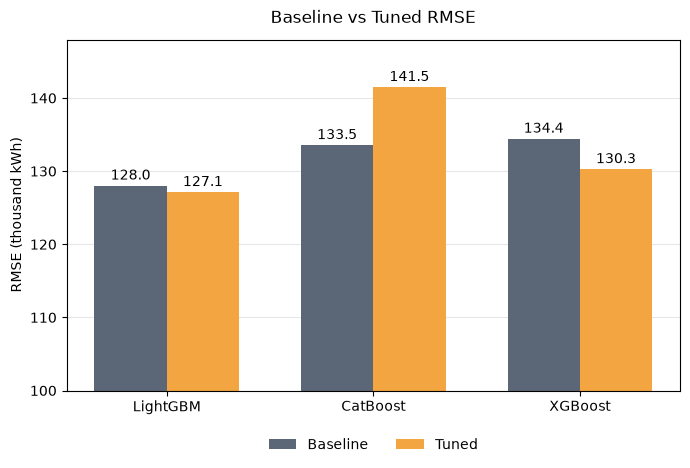

In [40]:
import matplotlib.pyplot as plt

plot_models = ["LightGBM", "CatBoost", "XGBoost"]
base  = baseline_results_df.set_index("Model").loc[plot_models, "RMSE"] / 1000
tuned = tuned_results_df.set_index("Model").loc[[f"Tuned {m}" for m in plot_models], "RMSE"] / 1000

x, w = np.arange(len(plot_models)), 0.35
fig, ax = plt.subplots(figsize=(7, 4.8))
bars1 = ax.bar(x - w / 2, base.values, w, label="Baseline", color="#5B6776")
bars2 = ax.bar(x + w / 2, tuned.values, w, label="Tuned", color="#F2A541")
ax.bar_label(bars1, fmt="%.1f", padding=2)
ax.bar_label(bars2, fmt="%.1f", padding=2)
ax.set_xticks(x)
ax.set_xticklabels(plot_models)
ax.set_ylim(100, 148)          # note: the y-axis starts at 100
ax.set_ylabel("RMSE (thousand kWh)")
ax.set_title("Baseline vs Tuned RMSE", pad=12)
ax.grid(axis="y", alpha=0.3)
ax.set_axisbelow(True)
# legend below the plot so it never covers the bars
ax.legend(loc="upper center", bbox_to_anchor=(0.5, -0.1), ncol=2, frameon=False)
plt.tight_layout()
plt.show()

### 13. Save the Best Model

In [21]:
import joblib

In [22]:
# 4. Save to disk
path = r"D:\OJT\Solar_Energy_Production_Analysis\best_solar_model.pkl"

joblib.dump(best_model, path)

print(f"Best model successfully saved to '{path}'!")

Best model successfully saved to 'D:\OJT\Solar_Energy_Production_Analysis\best_solar_model.pkl'!


### 14. Summary

* **Best model:** Tuned LightGBM (RMSE 127,129 kWh, MAE 9,398 kWh, R² 0.835 on the test set).
* Boosting models clearly beat Linear Regression, and tuning gave only small gains.
* **Limitation:** the models do not use PV system size, so they cannot explain individual project size, and MAE is about as large as a typical project's production. Including `kWdc` would give a near-perfect but trivial model (see section 5.1), so choose it according to the real use case.
* **Next steps:** widen the grids (especially CatBoost), pick the final model by cross-validation, add error plots/feature importance, and report additional metrics (median absolute error, RMSLE).